# Plotting photon data from gamma-ray bursts

#### This block of code imports the functions we need from the matplotlib and numpy libraries.

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

### In the code block below, enter in the appropriate fields for:

* `lightcurvefile`: enter the name of the light curve file you downloaded for the GRB we are studying. It should have the name format 'photon\_time\_energy\_...txt'.


* `t_interval`: To construct the light curve for the gamma-ray burst, we are going to count the number of photons that arrive per xxx second interval and plot that as a function of time. Pick a 'bin size' in units of seconds for your plot below. You can always change this later if you think a different bin size would suit your analysis better.


* `cut_time`: You can choose to cut out some data from the beginning or end of the dataset and focus your graph on the most interesting time range. For your first time through the data analysis, just say 'no' aka 0. If you do answer 'yes' or 1, set `tstart_cut` and `tstop_cut` to the number of seconds after the beginning of the dataset that you want to use as your time range. 

## Now you can run the next three blocks and produce a light curve for your gamma-ray burst

#### This block of code will print time for the earliest photon event in your dataset and the arrival times and energies of the least/most energetic photon events.

#### This block of code divides the time range of your data set into 'bins' and counts the number of photons that arrived at the detector in each time bin

#### Now we are plotting the number of photons detected as a function of time. The beginning of the gamma-ray burst should be really evident once you make this plot!

Earliest event time = np.float64(263607772.3704) s, MET
Lowest energy photon: energy= np.float64(30.54869)  MeV , arrival time =  263607795.508  s, MET
Hightest energy photon: energy= np.float64(29914.78)  MeV , arrival time =  263607782.7993  s, MET


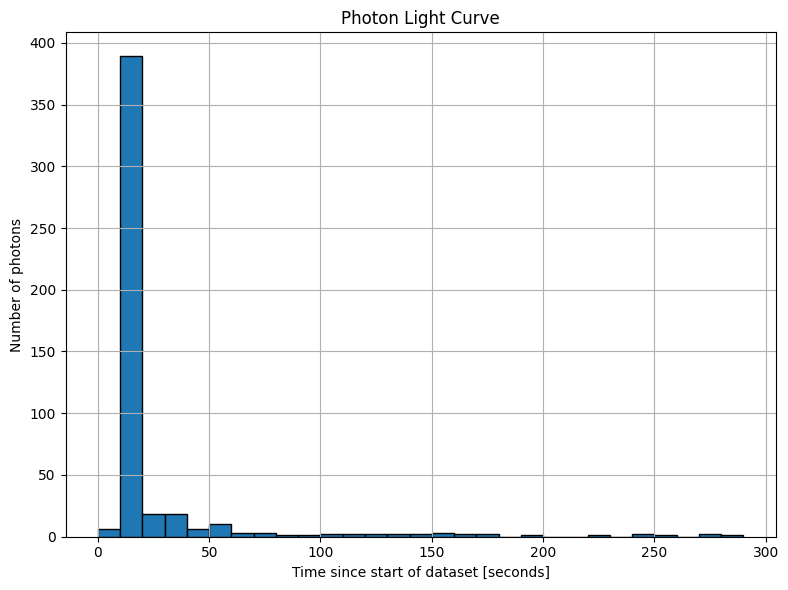

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


lightcurvefile = '../data/photon_time_energy_GRB090510.txt'  # Your light curve file
t_interval = 1  # Time interval for binning (seconds)
cut_time = 0  # No initial time cut

# Load data
energy, t0 = np.loadtxt(lightcurvefile, unpack=True)

# Shift all arrival times so earliest photon is at t=0
t0 = t0 - np.min(t0)

# Apply time cuts if needed (not used here)
if cut_time == 0:
    t = t0
else:
    tstart_cut = 10
    tstop_cut = 500
    mask = (t0 > tstart_cut) & (t0 < tstop_cut)
    t = t0[mask]

# --- Shift time so that 500 seconds corresponds to 0 seconds ---
t_shifted = t - 500

# Filter the shifted time data for the interval 0 to 500 seconds 
energy, t0 = np.loadtxt(lightcurvefile,unpack=True)
min_t = np.min(t0)
min_E = np.min(energy)
max_E = np.max(energy)
print ('Earliest event time = '+repr(min_t)+' s, MET')
print ('Lowest energy photon: energy=', repr(min_E), ' MeV , arrival time = ',t0[np.argmin(energy)],' s, MET')
print ('Hightest energy photon: energy=', repr(max_E), ' MeV , arrival time = ',t0[np.argmax(energy)],' s, MET')
# Shift all arrival times so the earliest photon is at t=0
t0 = t0 - min_t

# Apply time cuts if needed
if cut_time == 0:
    t = t0
else:
    mask = (t0 > tstart_cut) & (t0 < tstop_cut)
    t = t0[mask]
# Create histogram bins from 0 to the max time, using the specified interval
bins = np.arange(0, np.max(t)+t_interval, t_interval)
counts, bin_edges = np.histogram(t, bins=bins)


# Assuming t is already defined: t = array of photon arrival times
t_interval = 10  # Set bin size to 10 seconds

# Plot photon count histogram
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111)

# Define bin edges with 10-second intervals
bin_edges = np.arange(np.min(t), np.max(t) + t_interval, t_interval)
ax.hist(t, bins=bin_edges, edgecolor='black')

# Axis labels
ax.set_xlabel('Time since start of dataset [seconds]')
ax.set_ylabel('Number of photons')
ax.set_title("Photon Light Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


Earliest event time = 388741629.35 s, MET
Lowest energy photon: energy = 30.03738 MeV , arrival time = 388742015.3435 s, MET
Highest energy photon: energy = 94116.39 MeV , arrival time = 388741872.5497 s, MET


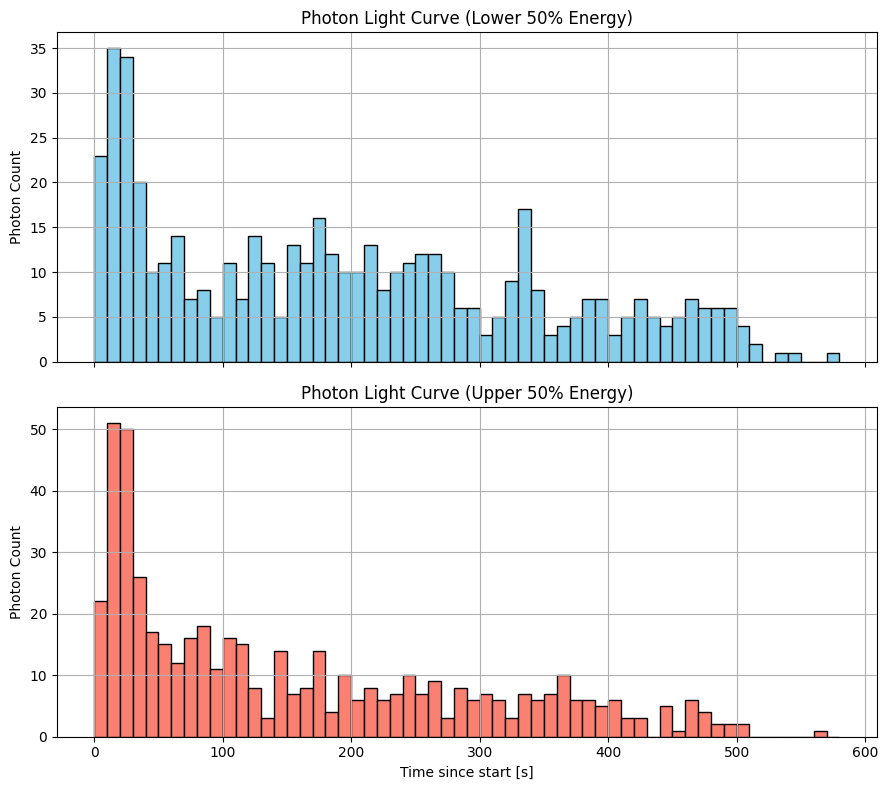

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

lightcurvefile = '../data/photon_time_energy_GRB130427A.txt'
t_interval = 10  # Bin size in seconds
cut_time = 0  # No cut

# Load energy and arrival times
energy, t0 = np.loadtxt(lightcurvefile, unpack=True)

# Print min/max info
min_t = np.min(t0)
min_E = np.min(energy)
max_E = np.max(energy)
print('Earliest event time =', min_t, 's, MET')
print('Lowest energy photon: energy =', min_E, 'MeV , arrival time =', t0[np.argmin(energy)], 's, MET')
print('Highest energy photon: energy =', max_E, 'MeV , arrival time =', t0[np.argmax(energy)], 's, MET')

# Shift arrival times so t=0 at earliest photon
t0 = t0 - min_t

# Apply time cuts if needed
if cut_time == 0:
    t = t0
    E = energy
else:
    tstart_cut = 10
    tstop_cut = 500
    mask = (t0 > tstart_cut) & (t0 < tstop_cut)
    t = t0[mask]
    E = energy[mask]

# Median energy split
median_E = np.median(E)
t_low = t[E <= median_E]
t_high = t[E > median_E]

# Define bin edges
bin_edges = np.arange(0, np.max(t) + t_interval, t_interval)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

ax1.hist(t_low, bins=bin_edges, color='skyblue', edgecolor='black')
ax1.set_title('Photon Light Curve (Lower 50% Energy)')
ax1.set_ylabel('Photon Count')
ax1.grid(True)

ax2.hist(t_high, bins=bin_edges, color='salmon', edgecolor='black')
ax2.set_title('Photon Light Curve (Upper 50% Energy)')
ax2.set_xlabel('Time since start [s]')
ax2.set_ylabel('Photon Count')
ax2.grid(True)

plt.tight_layout()
plt.show()



### Now, you want to focus your light curve plot on the time range that is most interesting, which starts approximately 5 seconds before the start of the burst and ends about 5 seconds after you think the photon detection rate has gone back down to what it was before the burst. To do so, you can either (1) use the interactive zoom tool (white rectangle) or (2) go through this notebook again and set the time cuts in the step where you entered in your filename and time bin size. 

### You can also change the bin size if you think it will make your plot more informative.